## Final Challenge: Suya Spot Report

In one notebook:
1. Load the data and make a copy.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# 1. Load the data and make a copy

original_orders = pd.read_csv("data/suya_orders.csv")

report_orders = original_orders.copy()

# Convert Date to datetime
report_orders["Date"] = pd.to_datetime(report_orders["Date"])

2. Clean it: handle the missing values and remove the duplicates.

In [6]:
report_orders["Customer_Age"] = report_orders[
    "Customer_Age"
].fillna(
    report_orders["Customer_Age"].median()
)

report_orders["Payment_Method"] = report_orders[
    "Payment_Method"
].fillna("Unknown")

report_orders = report_orders.drop_duplicates()

3. Show the average `Total_NGN` for each Branch.

In [7]:
# 3. Show average Total_NGN for each Branch

report_branch_average = (
    report_orders
    .groupby("Branch")["Total_NGN"]
    .mean()
    .sort_values(ascending=False)
)

print(report_branch_average)

Branch
Lagos Yaba           5702.312775
Abuja Wuse           4819.673123
Jos Terminus         4362.094763
Kano Sabon Gari      4246.656761
Ibadan Bodija        4207.449210
Kaduna Central       4097.458704
Port Harcourt GRA    3982.504970
Enugu Ogui           3963.080685
Name: Total_NGN, dtype: float64


4. Draw one chart.

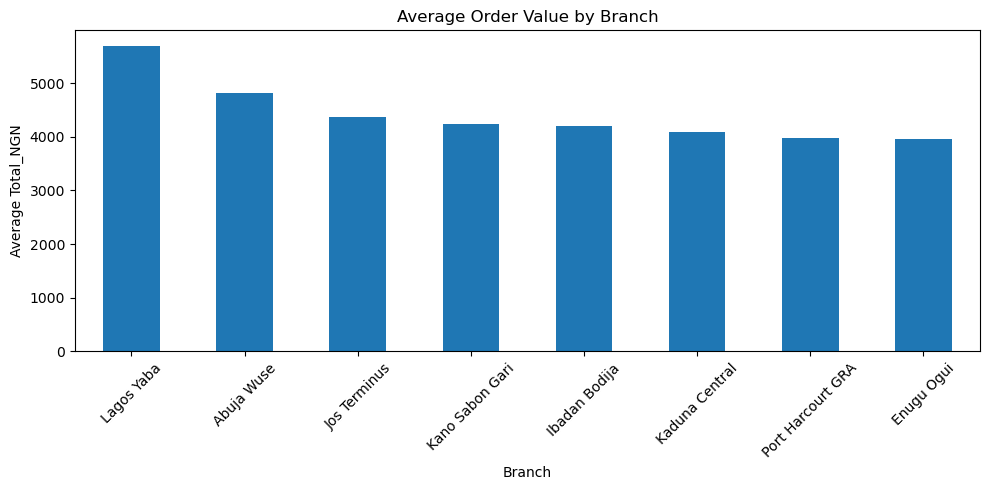

In [10]:
report_branch_average.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Order Value by Branch")
plt.xlabel("Branch")
plt.ylabel("Average Total_NGN")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

5. Write 3 sentences about what you found.

In [11]:
highest_average_branch = report_branch_average.idxmax()
highest_average_value = report_branch_average.max()

lowest_average_branch = report_branch_average.idxmin()
lowest_average_value = report_branch_average.min()

overall_average_value = report_orders["Total_NGN"].mean()

print(
    f"Highest average order value: {highest_average_branch} "
    f"- ₦{highest_average_value:,.2f}"
)

print(
    f"Lowest average order value: {lowest_average_branch} "
    f"- ₦{lowest_average_value:,.2f}"
)

print(
    f"Overall average order value: "
    f"₦{overall_average_value:,.2f}"
)

Highest average order value: Lagos Yaba - ₦5,702.31
Lowest average order value: Enugu Ogui - ₦3,963.08
Overall average order value: ₦4,541.14
